# Políticas y semáforos: los umbrales son política, nunca regulación

- **Nivel:** 1, Fundamentos
- **Requisitos previos:** el cuaderno 02 de este tema (un primer TestResult)
- **Tiempo de lectura:** unos 25 minutos

## Objetivos

Al terminar este cuaderno puedes:

- leer la `Policy` por defecto del motor y decir qué significa cada tipo de umbral;
- clasificar un valor p o una métrica en una luz a mano y con `Policy.classify`;
- construir una política más estricta y otra más permisiva y mostrar que el estadístico y el valor p no cambian mientras cambia el color;
- explicar por qué Contraste expresa cada luz como una lectura bajo una política con nombre, y nunca como un veredicto regulatorio.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.8.0 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import csv
import importlib.metadata as md
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.8.0
numpy 2.4.6
matplotlib 3.11.2


## Datos

Dos muestras puntuadas con una **verdad conocida**, versionadas en `data/examples/` como los ejemplos de la guía para traer tu propio modelo (`docs/guides/02_validate-your-own-model.md`). Ambas son sintéticas: el pipeline las genera desde una semilla (`data-pipeline/pipeline/io/examples.py`), de modo que no interviene ningún conjunto de datos de terceros ni su licencia, y las cubre la licencia MIT del repositorio.

- `scored_sample_development.csv`: 2.000 deudores observados el 2024-12-31 cuyas PD están calibradas por construcción: cada incumplimiento es un sorteo de Bernoulli a su propia PD.
- `scored_sample_current.csv`: 2.000 deudores observados el 2025-12-31 de una población más riesgosa, cuyos incumplimientos llegan a 1,5 veces la PD. El ordenamiento se mantiene y el nivel está subestimado en un tercio.
- Columnas: `id,observation_date,target,pd,segment`, donde `target` vale 1 si hubo incumplimiento en el horizonte.

Conocer la verdad permite hacerle una pregunta justa a una política: ¿encuentra la muestra que está mal y deja en paz a la que está bien? La celda siguiente lee ambos archivos con la biblioteca estándar (el cuaderno 04 los lee mediante el contrato 1) e imprime su nivel.

In [2]:
# Leer las dos muestras y comparar los incumplimientos con los que esperan las PD
ROOT = Path("../../..").resolve()
EXAMPLES = ROOT / "data" / "examples"


def read_sample(name):
    with open(EXAMPLES / f"scored_sample_{name}.csv", newline="", encoding="utf-8") as handle:
        rows = list(csv.DictReader(handle))
    return np.array([int(r["target"]) for r in rows]), np.array([float(r["pd"]) for r in rows])


samples = {name: read_sample(name) for name in ("development", "current")}
for name, (y, pd_hat) in samples.items():
    print(f"{name:12s} obligors: {len(y)} | defaults: {int(y.sum())} | defaults expected by the PDs: {pd_hat.sum():.1f} | mean PD: {pd_hat.mean():.4f}")

development  obligors: 2000 | defaults: 100 | defaults expected by the PDs: 111.2 | mean PD: 0.0556
current      obligors: 2000 | defaults: 207 | defaults expected by the PDs: 138.1 | mean PD: 0.0691


## Método

### Paso 1: qué es una política

Una `Policy` es una tabla de umbrales con nombre y versión, indexada por el identificador de la prueba. Las pruebas del motor nunca guardan un umbral: calculan un estadístico y un valor p, y la política lo convierte en una luz. Hay tres tipos de `Threshold`:

- `p_value`: rojo si el valor p es menor que `red`, ámbar si es menor que `amber`, verde en otro caso;
- `upper_bad` (más grande es peor, como el PSI): rojo en `red` o más, ámbar en `amber` o más;
- `lower_bad` (más pequeño es peor, como un AUC): rojo en `red` o menos, ámbar en `amber` o menos.

La celda siguiente abre la política por defecto del paquete y lee su descripción, los tipos que usa y los umbrales de las pruebas que llama este tema.

In [3]:
# Abrir la política por defecto: su etiqueta, descripción, tipos de umbral y algunos umbrales
policy = rv.default_policy()
print("label:", policy.label)
print("description:", policy.description)
print("thresholds by kind:", dict(Counter(t.kind for t in policy.thresholds.values())))
for test_id in ("pd.jeffreys", "pd.binomial", "stability.psi", "disc.auc_vs_initial", "disc.auc"):
    print(f"{test_id:22s}", policy.threshold(test_id))

label: riskvalidation-default 2026.10.1
description: Conventional thresholds for illustration and comparison. They are policy choices, not regulatory thresholds: the ECB 2019 IRB validation-reporting instructions set no pass or fail thresholds, and each entry names where its convention comes from. Institutions replace this file with their own policy.
thresholds by kind: {'p_value': 25, 'upper_bad': 16, 'lower_bad': 2}
pd.jeffreys            Threshold(kind='p_value', amber=0.05, red=0.01, source='convention: 5% and 1% significance levels; the ECB (2019) instructions and BCBS WP14 set no thresholds')
pd.binomial            Threshold(kind='p_value', amber=0.05, red=0.01, source='convention: 5% and 1% significance levels; the ECB (2019) instructions and BCBS WP14 set no thresholds')
stability.psi          Threshold(kind='p_value', amber=0.05, red=0.01, source='Yurdakul and Naranjo (2020) chi-square benchmark at 5% and 1%; the 0.10/0.25 bands are reported beside it as a rule of thumb withou

La descripción es lo primero que hay que leer: los umbrales son convenciones "para ilustración y comparación", y las instrucciones del BCE de 2019 no fijan umbrales de aprobación o rechazo. `disc.auc` no tiene umbral alguno, por lo que un resultado suyo nunca puede colorearse: su luz es `not_evaluated`.

### Paso 2: clasificar a mano

`Threshold.classify` es toda la regla, y `Policy.classify` busca el umbral por identificador de prueba y lo aplica. La celda siguiente clasifica tres valores p de la prueba de Jeffreys, y luego un valor tipo PSI con un umbral `upper_bad` y uno tipo AUC con un umbral `lower_bad`. Los dos umbrales de la segunda parte son inventados para la ilustración.

In [4]:
# Clasificar tres valores p con la política, y luego dos valores con umbrales ilustrativos de los otros tipos
for p_value in (0.20, 0.03, 0.004):
    light, threshold = policy.classify("pd.jeffreys", p_value=p_value)
    print(f"pd.jeffreys p={p_value:<6} -> {light.value:6s} (amber below {threshold.amber}, red below {threshold.red})")

upper = rv.Threshold(kind="upper_bad", amber=0.10, red=0.25)
lower = rv.Threshold(kind="lower_bad", amber=0.60, red=0.50)
print("upper_bad, value 0.12 ->", upper.classify(0.12).value)
print("lower_bad, value 0.55 ->", lower.classify(0.55).value)
print("no value ->", upper.classify(None).value)

pd.jeffreys p=0.2    -> green  (amber below 0.05, red below 0.01)
pd.jeffreys p=0.03   -> amber  (amber below 0.05, red below 0.01)
pd.jeffreys p=0.004  -> red    (amber below 0.05, red below 0.01)
upper_bad, value 0.12 -> amber
lower_bad, value 0.55 -> amber
no value -> not_evaluated


### Paso 3: una prueba, dos muestras, la política por defecto

Ahora el motor. `pd_jeffreys` recibe el número de deudores, el de incumplimientos y la PD aplicada (aquí la PD media de la muestra), y aplica la política que se le da. La corremos sobre ambas muestras. La muestra de desarrollo debería quedar en paz y la actual debería ser encontrada.

In [5]:
# Correr la prueba de Jeffreys sobre ambas muestras bajo la política por defecto
from riskvalidation.validation import pd_jeffreys


def jeffreys_under(policy_in_use, name):
    y, pd_hat = samples[name]
    return pd_jeffreys(n=len(y), d=int(y.sum()), pd=float(pd_hat.mean()), policy=policy_in_use, model_id=name, segment="portfolio")


for name in samples:
    result = jeffreys_under(policy, name)
    print(f"{name:12s} p-value: {result.p_value:.3e} | light: {result.light.value:5s} | policy: {result.policy_version} | amber/red: {result.alpha_amber}/{result.alpha_red}")

development  p-value: 8.629e-01 | light: green | policy: riskvalidation-default 2026.10.1 | amber/red: 0.05/0.01
current      p-value: 6.047e-09 | light: red   | policy: riskvalidation-default 2026.10.1 | amber/red: 0.05/0.01


### Paso 4: el mismo valor p, otra política

Una política es un dato, por lo que una institución puede tener una más estricta o una más permisiva. La celda siguiente construye dos políticas para esta prueba: `strict-demo` pasa a ámbar bajo 0,90 y a rojo bajo 0,50, y `lenient-demo` pasa a ámbar bajo 1e-6 y a rojo bajo 1e-9. Ambas son ilustraciones, no recomendaciones. Luego corremos la misma prueba, sobre los mismos arreglos, bajo las tres políticas.

In [6]:
# Construir dos políticas para una prueba y leer los mismos valores p bajo las tres
strict = rv.Policy(policy_id="strict-demo", version="1", description="illustration: a stricter reading of one test",
                   thresholds={"pd.jeffreys": rv.Threshold(kind="p_value", amber=0.90, red=0.50)})
lenient = rv.Policy(policy_id="lenient-demo", version="1", description="illustration: a more lenient reading of one test",
                    thresholds={"pd.jeffreys": rv.Threshold(kind="p_value", amber=1e-6, red=1e-9)})

for name in samples:
    for in_use in (policy, strict, lenient):
        result = jeffreys_under(in_use, name)
        print(f"{name:12s} {in_use.policy_id:26s} p-value: {result.p_value:.3e} | light: {result.light.value}")

development  riskvalidation-default     p-value: 8.629e-01 | light: green
development  strict-demo                p-value: 8.629e-01 | light: amber
development  lenient-demo               p-value: 8.629e-01 | light: green
current      riskvalidation-default     p-value: 6.047e-09 | light: red
current      strict-demo                p-value: 6.047e-09 | light: red
current      lenient-demo               p-value: 6.047e-09 | light: amber


El valor p es idéntico bajo las tres políticas; solo se mueve la luz. Todo `TestResult` registra la etiqueta de la política que lo coloreó y los dos puntos de corte (`alpha_amber`, `alpha_red`), de modo que una luz siempre se puede releer bajo otra política sin correr la prueba otra vez.

### Paso 5: una política es un archivo con versión

El motor entrega su política por defecto como un archivo JSON, y `load_policy` lee un archivo de esa forma. La celda siguiente escribe la forma de una política como texto, la lee de vuelta con `policy_from_mapping` (la función que `load_policy` llama después de leer el archivo) y comprueba que se comporta como la original. No se escribe ningún archivo.

In [7]:
# Escribir la forma de un archivo de política como texto, leerlo de vuelta y comprobar que se comporta como el original
from riskvalidation.core.policy import policy_from_mapping

text = json.dumps({
    "policy_id": "strict-demo",
    "version": "1",
    "description": "illustration: a stricter reading of one test",
    "thresholds": {"pd.jeffreys": {"kind": "p_value", "amber": 0.90, "red": 0.50, "source": "illustration"}},
}, indent=2)
print(text)

reloaded = policy_from_mapping(json.loads(text))
print("same label:", reloaded.label == strict.label)
print("same threshold:", reloaded.threshold("pd.jeffreys").amber == strict.threshold("pd.jeffreys").amber)
print("same light on the development sample:", jeffreys_under(reloaded, "development").light == jeffreys_under(strict, "development").light)

{
  "policy_id": "strict-demo",
  "version": "1",
  "description": "illustration: a stricter reading of one test",
  "thresholds": {
    "pd.jeffreys": {
      "kind": "p_value",
      "amber": 0.9,
      "red": 0.5,
      "source": "illustration"
    }
  }
}
same label: True
same threshold: True
same light on the development sample: True


### Paso 6: las luces, dibujadas

La última celda pone los dos valores p en un eje logarítmico, con los puntos de corte de las tres políticas como líneas verticales. Un punto a la izquierda de una línea está por debajo de ese umbral.

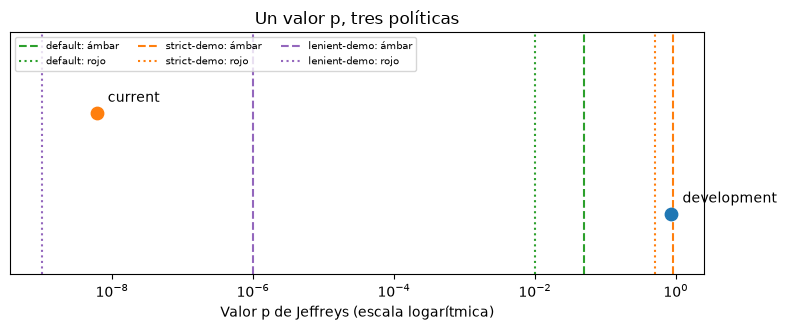

In [8]:
# Dibujar los dos valores p frente a los puntos de corte de las tres políticas
fig, ax = plt.subplots(figsize=(8, 3.4))
p_values = {name: jeffreys_under(policy, name).p_value for name in samples}
for row, (name, p_value) in enumerate(p_values.items()):
    ax.scatter([p_value], [row], s=80, zorder=3)
    ax.annotate(name, (p_value, row), textcoords="offset points", xytext=(8, 8))

KINDS = ("ámbar", "rojo")
styles = (("default", policy, "tab:green"), ("strict-demo", strict, "tab:orange"), ("lenient-demo", lenient, "tab:purple"))
for label, in_use, color in styles:
    cut = in_use.threshold("pd.jeffreys")
    ax.axvline(cut.amber, color=color, linestyle="--", label=f"{label}: {KINDS[0]}")
    ax.axvline(cut.red, color=color, linestyle=":", label=f"{label}: {KINDS[1]}")
ax.set_xscale("log")
ax.set_yticks([])
ax.set_ylim(-0.6, 1.8)
ax.set_xlabel("Valor p de Jeffreys (escala logarítmica)")
ax.set_title("Un valor p, tres políticas")
ax.legend(fontsize=7, ncol=3, loc="upper left")
fig.tight_layout()
plt.show()

## Resultados

- **Bajo la política por defecto se encuentra la verdad.** La muestra de desarrollo, calibrada por construcción, es verde (p = 0,86). La muestra actual, con 207 incumplimientos donde sus PD esperan unos 138, es roja (p del orden de 1e-9).
- **El color es una lectura, no una propiedad.** La política estricta pasa a ámbar la muestra de desarrollo calibrada sin ningún cambio en los datos ni en el valor p, y la permisiva pasa a ámbar la muestra actual, que era roja. Una luz solo tiene sentido junto con la política que la produjo, y el `TestResult` lleva esa etiqueta por esta razón.
- **Los umbrales ausentes se ven.** Una prueba sin umbral en la política, como el AUC, devuelve `not_evaluated`. Nunca es verde en silencio.

Esta es la regla de redacción de todo el producto: una luz de Contraste dice "bajo la política `riskvalidation-default 2026.10.1`, el valor p es menor que 0,01"; nunca dice que un modelo cumple o no cumple. Los supervisores no fijan tales umbrales en las fuentes que cita el motor (ECB 2019; BCBS Working Paper 14, 2005), y la descripción de la política lo dice. Lo que este cuaderno no hace es elegir una política por ti: eso corresponde a la función de riesgo de modelos de la institución.

## Resumen

- Una `Policy` es un dato con versión que asigna a un identificador de prueba un `Threshold` de tipo `p_value`, `upper_bad` o `lower_bad`; las pruebas no guardan umbrales.
- El mismo estadístico y valor p dan luces distintas bajo políticas distintas, y el resultado registra la etiqueta de la política y los puntos de corte.
- Una prueba sin umbral es `not_evaluated`, nunca verde.
- Los umbrales son política de una institución; las fuentes que cita el motor no fijan ninguno.

**Qué probar a continuación.** Agrega a una política propia un umbral para `disc.auc` (tipo `lower_bad`) y vuelve a correr bajo ella el AUC del cuaderno 02. Luego sigue con el cuaderno 04, que corre una batería completa bajo una sola política.

## Referencias

- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk: definen las pruebas y no fijan umbrales de aprobación o rechazo. https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- BCBS (2005), Studies on the validation of internal rating systems, Working Paper 14 (revised). https://www.bis.org/publications/studies-validation-internal-rating-systems-revised.pdf
- Brown, L. D., Cai, T. T. y DasGupta, A. (2001), Interval estimation for a binomial proportion, Statistical Science 16(2), el intervalo de Jeffreys detrás de la prueba. https://doi.org/10.1214/ss/1009213286
- Este repositorio: `docs/design/SDD.md` (no objetivo 1: ninguna luz es un veredicto de cumplimiento) y `docs/guides/02_validate-your-own-model.md`.